In [219]:
import numpy as np
from scipy import io
import matplotlib.pyplot as plt
from src.utils import setup_plot_style, import_vars_from_matlab
from LinearExperiment import LinearAnalysis
from ActivityPipelines import ActivityLoader
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os

colors = setup_plot_style()

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'
session = r'250225_SAM032'

session_path = os.path.join(data_dir, session)
results_path = create_new_result_dir(session_path, r'results')
stimulus_path = os.path.join(session_path, r'stimulus')
activity_path = os.path.join(session_path, r'suite2p\plane0')

# check files inside stimulus_path
filelist = [file for file in os.listdir(stimulus_path) if file.endswith(("_stimulus.mat"))]
if len(filelist) == 0:
    # raise error
    raise Exception('No stimulus file found')
elif len(filelist) > 1:
    raise Exception('More than one stimulus file found')
else:
    print('Stimulus file found')

container = io.loadmat(stimulus_path + '/' + str(filelist[0]))

D = ActivityLoader(session_path)
frames_time = D.frames_time

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Directory results already exists
Stimulus file found


In [148]:
time = []
stepper_pos = []
servo_id = []
mini_servo_active = []
trial_sequence = []
history_sequence = []
trial_start_time = []
trial_end_time = []

field_names = import_vars_from_matlab(container, 'stim', locals())

stepper_pos_interp = np.interp(D.frames_time, time, stepper_pos)
on_time_interp = np.round(np.interp(D.frames_time, time, mini_servo_active)).astype(bool)
identity_interp = np.round(np.interp(D.frames_time, time, servo_id)).astype(int)

In [63]:
def create_monocular_sequence(trial_sequence_length):
    # Create array of the same length as trial_sequence
    monocular_sequence = np.zeros(trial_sequence_length, dtype=bool)

    # Calculate quarter points
    quarter = trial_sequence_length // 4

    # Set first quarter to True
    monocular_sequence[:quarter] = True

    # Set third quarter to True
    monocular_sequence[2*quarter:3*quarter] = True

    return monocular_sequence

In [65]:
monocular_sequence = create_monocular_sequence(len(trial_sequence))

[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
 False False False False False False False False False False False False
 False False False False False False False False False False False False
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
 False False False False False False False False False False False False
 False False False False False False False False False False False False]


In [107]:
def find_suite2p_cell(suite2p_cell_id):
    return np.where(D.suite2p_id == suite2p_cell_id)[0]

In [185]:
# Create a figure
# Pastel color scheme - first color stronger than second for each type
colors = [
    ['#5CB8E4', '#CAE5FF'],   # Blues: [0][0]=Strong Blue, [0][1]=Light Blue
    ['#7DCE82', '#D8E2DC'],   # Greens: [1][0]=Strong Green, [1][1]=Light Green
    ['#FF9AA2', '#FFCAD4']    # Reds: [2][0]=Strong Red, [2][1]=Light Red
]

In [271]:
def get_trial_frames(repeat):

    trial_start = 1000*trial_start_time[repeat]
    trial_end = 1000*trial_end_time[repeat]

    return (frames_time > trial_start) & (frames_time < trial_end)

def get_on_times(repeat):

    trial_start = 1000*trial_start_time[repeat]
    trial_end = 1000*trial_end_time[repeat]

    return (frames_time > trial_start) & (frames_time < trial_end) & on_time_interp

def get_on_trace(cell, repeat):

    on_frames = get_on_times(repeat)

    return D.dFF[cell, on_frames][:40]

def get_all_on_traces(cell):

    all_traces = []

    for repeat in range(len(trial_sequence[:-1])):

        on_trace = get_on_trace(cell, repeat)[:40]
        all_traces.append(on_trace)

    return all_traces

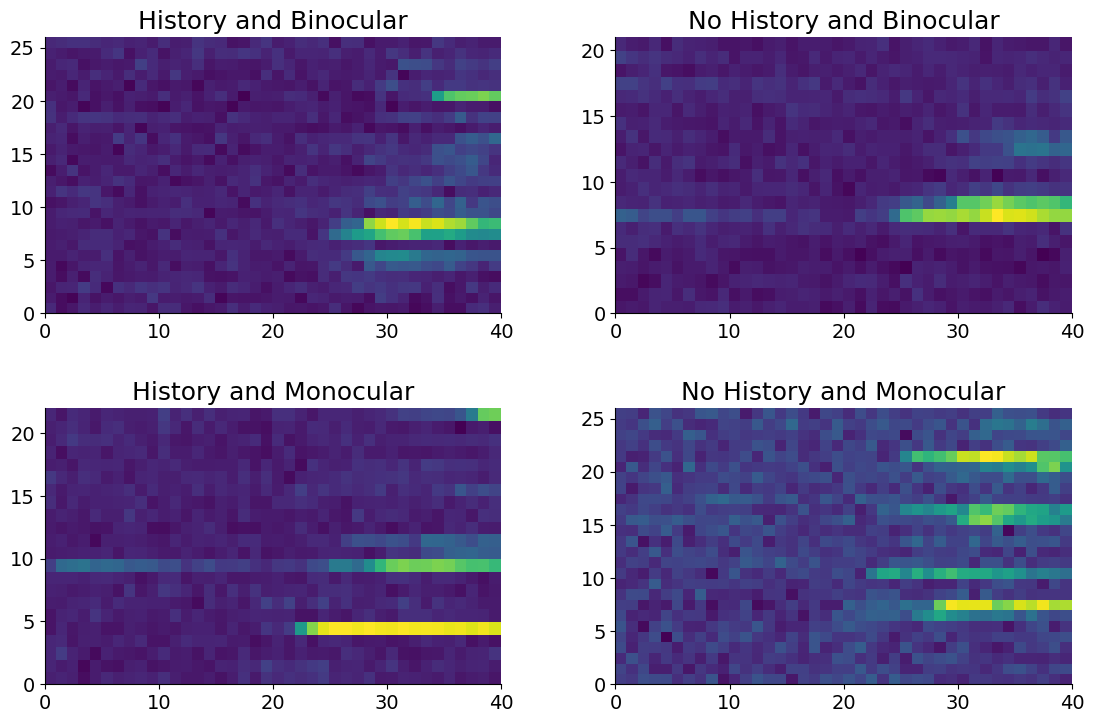

In [283]:
cell = find_suite2p_cell(92)

fig, ax = plt.subplots(2,2, figsize=(12, 8))
# add padding
fig.tight_layout(pad=3.0)

no_history_binocular = []
history_binocular = []
no_history_monocular = []
history_monocular = []

for rep in range(len(trial_sequence[:-1])):

    repeat_trace = get_on_trace(cell, rep)

    if history_sequence[rep] and ~monocular_sequence[rep]:
        history_binocular.append(np.array(repeat_trace))

    elif ~history_sequence[rep] and ~monocular_sequence[rep]:
        no_history_binocular.append(np.array(repeat_trace))

    elif history_sequence[rep] and monocular_sequence[rep]:
        history_monocular.append(np.array(repeat_trace))

    elif ~history_sequence[rep] and monocular_sequence[rep]:
        no_history_monocular.append(np.array(repeat_trace))

# # add titles
ax[0,0].set_title('History and Binocular')
ax[0,0].pcolor(np.array(history_binocular), cmap='viridis')
ax[0,1].set_title('No History and Binocular')
ax[0,1].pcolor(np.array(no_history_binocular), cmap='viridis')
ax[1,0].set_title('History and Monocular')
ax[1,0].pcolor(np.array(history_monocular), cmap='viridis')
ax[1,1].set_title('No History and Monocular')
ax[1,1].pcolor(np.array(no_history_monocular), cmap='viridis')

plt.show()

In [220]:
for id in range(0,300):

    cell= find_suite2p_cell(id)

    repeats = [0, 24]
    start = trial_start_time[repeats[0]]*1000
    end = trial_end_time[repeats[1]]*1000
    repeats_time = (D.frames_time > start) & (D.frames_time < end)

    plt.figure(figsize=(20, 5))
    plt.plot(D.frames_time[repeats_time], D.dFF[cell, repeats_time].T)

    for rep in range(repeats[0], repeats[1]):

        on_time_frames = get_on_times(rep)
        on_start = frames_time[on_time_frames][0]
        on_end = frames_time[on_time_frames][-1]

        c = colors[trial_sequence[rep]-1]

        if history_sequence[rep]:
            plt.fill_between([on_start, on_end], 0, 10, hatch= '---', linewidth=5, edgecolor='black', color = c, alpha=0.4)
        else:
            plt.fill_between([on_start, on_end], 0, 10, color = c, alpha=0.3)

        plt.fill_between([on_start, on_end], 0, 10, color = c, alpha=0.4)

    plt.savefig(results_path + '/cell_' + str(id) + '.png')
    plt.close()
#     on_time_frames = get_on_times(repeats)
#     on_start = frames_time[on_time_frames][0]
#     on_end = frames_time[on_time_frames][-1]
#
#     ax1.fill_between([on_start, on_end], min_spks, max_spks, alpha=0.4)

IndexError: shape mismatch: indexing arrays could not be broadcast together with shapes (0,) (3543,) 

<Figure size 2000x500 with 0 Axes>

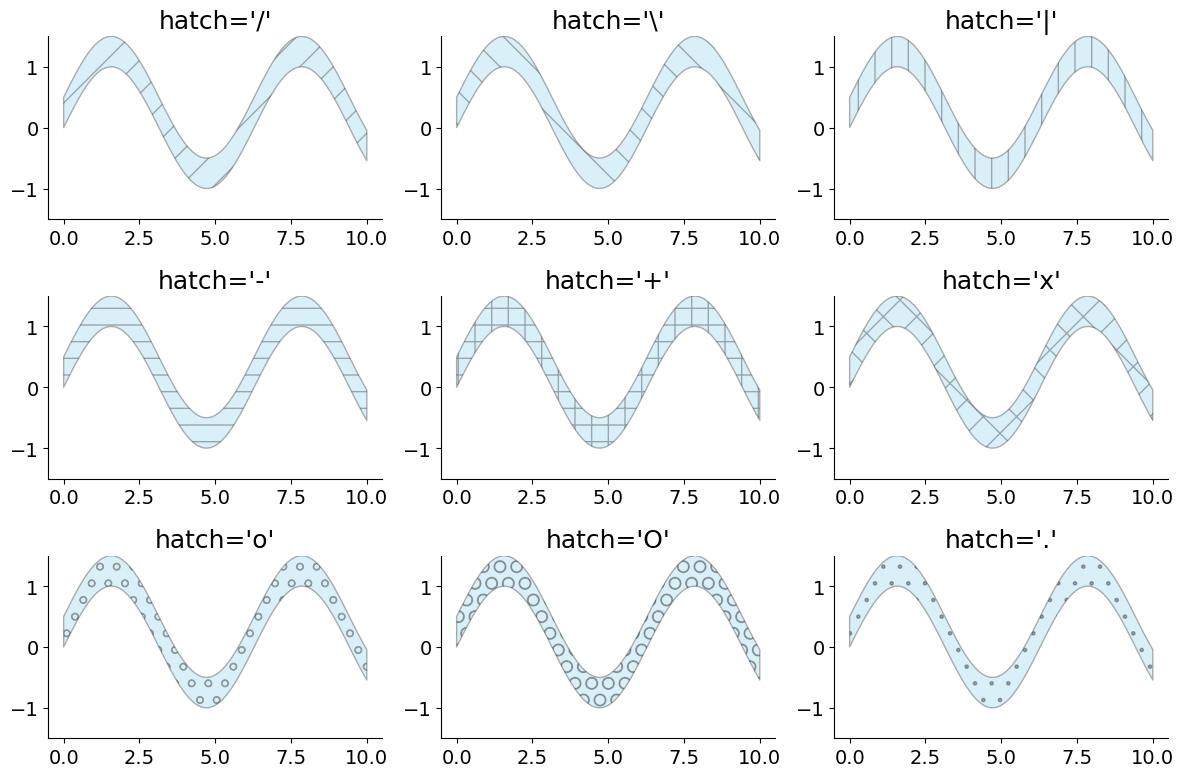

In [197]:
x = np.linspace(0, 10, 100)
y1 = np.sin(x)
y2 = y1 + 0.5

fig, axs = plt.subplots(3, 3, figsize=(12, 8))
axs = axs.flatten()

patterns = ['/', '\\', '|', '-', '+', 'x', 'o', 'O', '.']

for i, pattern in enumerate(patterns):
    axs[i].fill_between(x, y1, y2,
                       hatch=pattern,
                       alpha=0.3,  # transparency
                       edgecolor='black',
                       facecolor='skyblue')
    axs[i].set_title(f"hatch='{pattern}'")
    axs[i].set_ylim(-1.5, 1.5)

plt.tight_layout()
plt.show()

In [187]:
print(trial_sequence)

[2 3 1 1 1 1 2 1 2 1 2 2 2 2 1 2 1 1 3 3 2 3 1 2 2 2 3 1 2 1 1 1 2 1 1 3 2
 1 2 2 3 1 1 1 1 3 1 2 3 2 1 3 3 3 3 3 3 1 1 2 1 3 3 2 3 1 2 3 2 3 2 2 2 3
 2 3 1 2 3 3 1 3 3 2 3 3 2 1 2 3 3 1 3 2 3 1]


1 True True
Trial start: 128669.47709999999
Trial end: 145700.0794
171


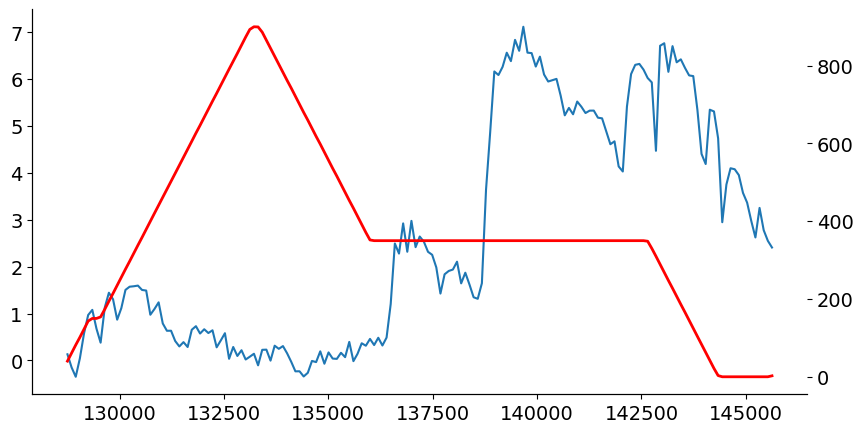

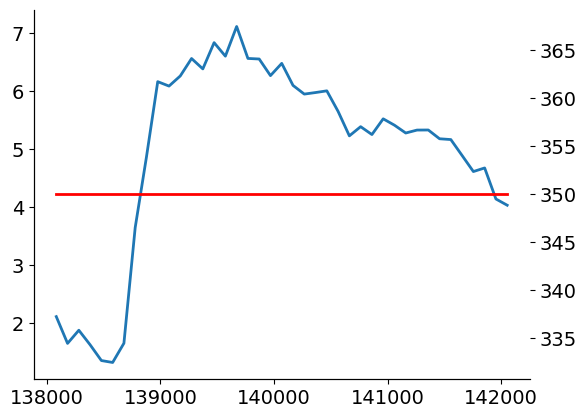

In [156]:
repeat = 9
cell = find_suite2p_cell(82)

repeat_id = trial_sequence[repeat]
is_history = bool(history_sequence[repeat])
is_monocular = monocular_sequence[repeat]
print(repeat_id, is_history, is_monocular)

repeat_frames = get_trial_frames(repeat)
on_frames = get_on_times(repeat)

print(np.sum(repeat_frames))

plt.figure(figsize=(10, 5))

# do two mirror axis
ax = plt.gca()
ax2 = ax.twinx()

ax.plot(frames_time[repeat_frames], D.dFF[cell, repeat_frames].T)
ax2.plot(frames_time[repeat_frames], stepper_pos_interp[repeat_frames], lw=2, color='red')

plt.figure()
ax = plt.gca()
ax2 = ax.twinx()

ax.plot(frames_time[on_frames], D.dFF[cell, on_frames].T, lw=2)
ax2.plot(frames_time[on_frames], stepper_pos_interp[on_frames], lw=2, color='red')

In [76]:
repeat_frames = get_trial_frames(0)


In [ ]:
stepper_pos_interp = np.interp(D.frames_time, time, stepper_pos)[:delta_time]
on_time_interp = np.round(np.interp(D.frames_time, time, mini_servo_active)).astype(int)[:delta_time]
identity_interp = np.round(np.interp(D.frames_time, time, servo_id)).astype(int)[:delta_time]

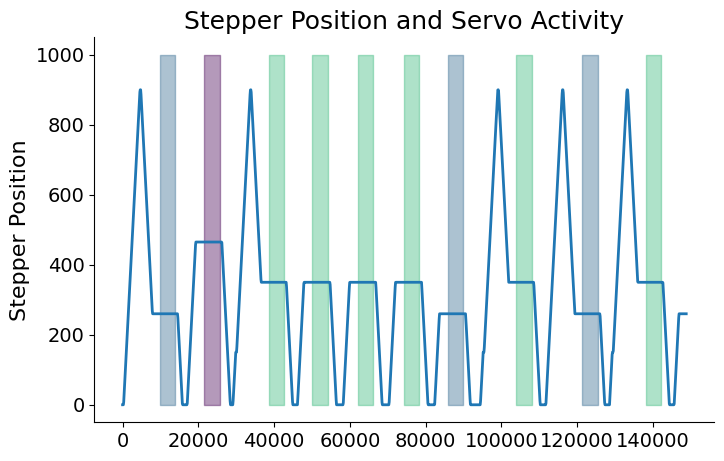

In [48]:
# First would be to organize repeats, for history and not history
delta_time = 1500


# Create figure with two subplots
fig, ax1 = plt.subplots(1, 1, figsize=(8, 5))

# Plot stepper position in the first subplot
ax1.plot(D.frames_time[:delta_time], stepper_pos_interp, lw=2)
ax1.set_ylabel('Stepper Position')
ax1.set_title('Stepper Position and Servo Activity')

for i in [1,2,3]:
    ax1.fill_between(D.frames_time[:delta_time], 0, 1000*on_time_interp,
                     where=((on_time_interp > 0) & (identity_interp == i)), color=colors[i], alpha=0.4,
                     step='post', label='Servo Active')

In [ ]:
# Visualize neural activity

